# 🏠 Housing Price AutoResearch — Optuna TPE
**Bayesian optimizasyon · geçmişten öğrenir · Ctrl+C ile durdur**

In [1]:
# Hücre 1 — Kurulum ve import
# Optuna yoksa: pip install optuna
import warnings; warnings.filterwarnings('ignore')

try:
    import optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    print(f'✅ Optuna {optuna.__version__}')
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'optuna', '-q'])
    import optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    print(f'✅ Optuna yüklendi: {optuna.__version__}')

import numpy as np
import pandas as pd
import time, traceback, pprint
from sklearn.ensemble import (RandomForestRegressor, ExtraTreesRegressor,
                               HistGradientBoostingRegressor, VotingRegressor)
from sklearn.metrics import r2_score
from sklearn.model_selection import KFold, train_test_split
from sklearn.preprocessing import LabelEncoder
print('✅ Kütüphaneler hazır.')


✅ Optuna 4.8.0
✅ Kütüphaneler hazır.


In [2]:
# 1. Dosya Adı ve Yolu
file_path = 'ankara.xlsx'

# 2. Veri Yükleme ve Hata Kontrolü

df = pd.read_excel(file_path)
    
print(f"'{file_path}' dosyası başarıyla yüklendi.")
    
    # 3. İlk Kontroller
print("\n--- Veri Seti Bilgileri ---")
print(f"Satır Sayısı: {df.shape[0]}, Sütun Sayısı: {df.shape[1]}")
print("\nİlk 5 Satır:")
print(df.head())
    
print("\nVeri Tipleri ve Eksik Bilgi Özeti:")
df.info()

'ankara.xlsx' dosyası başarıyla yüklendi.

--- Veri Seti Bilgileri ---
Satır Sayısı: 998, Sütun Sayısı: 8

İlk 5 Satır:
       Price province   district              street  Room   m2  floor  age
0   42500000  Ankara    Gölbaşı      Gökçehüyük Mah.     2  100     -1    0
1   42750000  Ankara    Gölbaşı      Gökçehüyük Mah.     2  100      0    0
2   10900000  Ankara    Polatlı         Gedikli Mah.     5  100     -1    0
3  499000000  Ankara    Gölbaşı      Kızılcaşar Mah.     5  100     -1    0
4   26500000  Ankara    Gölbaşı    Bahçelievler Mah.     6  100     -1    0

Veri Tipleri ve Eksik Bilgi Özeti:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 998 entries, 0 to 997
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Price     998 non-null    int64 
 1   province  998 non-null    object
 2   district  998 non-null    object
 3   street    998 non-null    object
 4   Room      998 non-null    int64 
 5   m2        998

In [3]:
# Hücre 2 — df kontrolü (zaten bellekteyse sadece çalıştır)
# df = pd.read_csv('konut.csv')   # <-- gerekirse aç
print(f'Satır: {len(df):,}  |  Sütunlar: {list(df.columns)}')
df.head(3)


Satır: 998  |  Sütunlar: ['Price', 'province', 'district', 'street', 'Room', 'm2', 'floor', 'age']


,Price,province,district,street,Room,m2,floor,age
0,42500000,Ankara,Gölbaşı,Gökçehüyük Mah.,2,100,-1,0
1,42750000,Ankara,Gölbaşı,Gökçehüyük Mah.,2,100,0,0
2,10900000,Ankara,Polatlı,Gedikli Mah.,5,100,-1,0


In [4]:
# Hücre 3 — Pipeline motoru (değiştirme)
RESULTS_FILE       = 'results.tsv'
BEST_PIPELINE_FILE = 'best_pipeline.txt'
RANDOM_SEED        = 42

# ─────────────────────────────────────────
def _remove_outliers(df, strategy, hi):
    if strategy == 'none':
        return df
    if strategy == 'pct':
        lo_v, hi_v = df['Price'].quantile([hi, 1-hi])
        return df[(df['Price'] >= lo_v) & (df['Price'] <= hi_v)]
    if strategy == 'iqr':
        q1, q3 = df['Price'].quantile([0.25, 0.75])
        iqr = q3 - q1
        return df[(df['Price'] >= q1 - hi*iqr) & (df['Price'] <= q3 + hi*iqr)]
    if strategy == 'log_z':
        lp = np.log1p(df['Price'])
        z  = (lp - lp.mean()) / lp.std()
        return df[np.abs(z) <= hi]
    if strategy == 'district':
        parts = []
        for _, grp in df.groupby('district'):
            lp  = np.log1p(grp['Price'])
            med = np.median(lp)
            mad = np.median(np.abs(lp - med)) + 1e-6
            parts.append(grp[np.abs(lp - med) / mad <= hi])
        return pd.concat(parts)
    return df

def _apply_target(y, tf):
    if tf == 'log1p': return np.log1p(y)
    if tf == 'sqrt':  return np.sqrt(y.clip(0))
    if tf == 'cbrt':  return np.cbrt(y)
    return y.astype(float)

def _invert_target(yhat, tf):
    if tf == 'log1p': return np.expm1(yhat)
    if tf == 'sqrt':  return yhat ** 2
    if tf == 'cbrt':  return yhat ** 3
    return yhat

def _encode_col(tr, val, col, strategy, y_tr):
    if strategy == 'label':
        le = LabelEncoder()
        le.fit(tr[col].astype(str))
        cls_set = set(le.classes_)
        tr_enc  = le.transform(tr[col].astype(str))
        val_enc = val[col].astype(str).map(
            lambda x: le.transform([x])[0] if x in cls_set else 0).values
        return tr_enc, val_enc
    if strategy == 'frequency':
        freq = tr[col].value_counts().to_dict()
        return (tr[col].map(freq).fillna(0).values,
                val[col].map(freq).fillna(0).values)
    if strategy in ('target_mean', 'target_median'):
        fn      = np.mean if strategy == 'target_mean' else np.median
        global_ = fn(y_tr)
        tmp     = pd.DataFrame({col: tr[col].values, '_y': y_tr})
        mapping = tmp.groupby(col)['_y'].agg(fn).to_dict()
        return (tr[col].map(mapping).fillna(global_).values,
                val[col].map(mapping).fillna(global_).values)
    if strategy == 'ordinal_by_freq':
        order = {v: i for i, v in enumerate(tr[col].value_counts().index, 1)}
        return (tr[col].map(order).fillna(0).values,
                val[col].map(order).fillna(0).values)
    return _encode_col(tr, val, col, 'label', y_tr)

def _build_features(df_tr, df_val, enc_strategy, feat_set, use_stats, y_tr_arr):
    tr  = df_tr.copy().reset_index(drop=True)
    val = df_val.copy().reset_index(drop=True)
    features = []

    for col in ['province', 'district', 'street']:
        te, ve = _encode_col(tr, val, col, enc_strategy, y_tr_arr)
        tr[col+'_enc'] = te;  val[col+'_enc'] = ve
        features.append(col+'_enc')

    features += ['Room', 'm2', 'floor', 'age']
    for d in (tr, val):
        d['log_m2']      = np.log1p(d['m2'])
        d['floor_abs']   = d['floor'].clip(0, 50)
        d['is_ground']   = (d['floor'] == 0).astype(int)
        d['is_basement'] = (d['floor'] < 0).astype(int)
        d['age_bin']     = pd.cut(d['age'], bins=[-1,0,5,15,30,200],
                                   labels=[0,1,2,3,4]).cat.codes.replace(-1, 0)
        d['is_new']      = (d['age'] == 0).astype(int)
        d['is_old']      = (d['age'] > 30).astype(int)
    features += ['log_m2','floor_abs','is_ground','is_basement','age_bin','is_new','is_old']

    if feat_set in ('extended', 'full'):
        for d in (tr, val):
            d['room_m2']       = d['Room'] * d['m2']
            d['room_m2_ratio'] = d['Room'] / (d['m2'] + 1)
            d['sqrt_m2']       = np.sqrt(d['m2'])
            d['m2_sq']         = d['m2'] ** 2
            d['floor_age']     = d['floor_abs'] / (d['age'] + 1)
            d['floor_m2']      = d['floor_abs'] * d['m2']
        features += ['room_m2','room_m2_ratio','sqrt_m2','m2_sq','floor_age','floor_m2']

    if use_stats:
        tr['_y'] = y_tr_arr
        for col in ['district', 'street']:
            stats = tr.groupby(col)['_y'].agg(['mean','median','std','count']).rename(
                columns={'mean':col+'_ym','median':col+'_ymed',
                         'std':col+'_ystd','count':col+'_cnt'})
            stats[col+'_ystd'] = stats[col+'_ystd'].fillna(0)
            for suf, gv in [(col+'_ym', tr['_y'].mean()),
                            (col+'_ymed', tr['_y'].median()),
                            (col+'_ystd', 0), (col+'_cnt', 1)]:
                tr[suf]  = tr[col].map(stats[suf]).fillna(gv)
                val[suf] = val[col].map(stats[suf]).fillna(gv)
                features.append(suf)
        dm2 = tr.groupby('district')['m2'].median()
        tr['dist_m2_med']  = tr['district'].map(dm2).fillna(tr['m2'].median())
        val['dist_m2_med'] = val['district'].map(dm2).fillna(tr['m2'].median())
        features.append('dist_m2_med')

    return tr[features].values.astype(float), val[features].values.astype(float), features

def run_experiment(df, p):
    """p = Optuna trial parametreleri dict'i"""
    data = _remove_outliers(df, p['outlier_strategy'], p['outlier_hi'])
    if len(data) < 500:
        raise ValueError('Outlier sonrası < 500 satır')

    if p['val_mode'] == 'split':
        tr_i, val_i = train_test_split(range(len(data)),
                                       test_size=p['val_test_size'],
                                       random_state=RANDOM_SEED)
        splits = [(data.iloc[tr_i], data.iloc[val_i])]
    else:
        kf = KFold(n_splits=p['val_n_splits'], shuffle=True, random_state=RANDOM_SEED)
        splits = [(data.iloc[ti], data.iloc[vi])
                  for ti, vi in kf.split(np.arange(len(data)))]

    r2_scores, last_model, last_feats = [], None, None
    for tr, val in splits:
        tf   = p['target_transform']
        y_tr = _apply_target(tr['Price'], tf)
        X_tr, X_val, feats = _build_features(
            tr, val, p['encoding'], p['feat_set'],
            p['use_stats'], y_tr.values)

        mt = p['model_type']
        if mt == 'rf':
            model = RandomForestRegressor(
                n_estimators=p['n_estimators'], max_depth=p['max_depth'] or None,
                min_samples_leaf=p['min_samples_leaf'],
                max_features=p['max_features'],
                n_jobs=-1, random_state=RANDOM_SEED)
        elif mt == 'et':
            model = ExtraTreesRegressor(
                n_estimators=p['n_estimators'], max_depth=p['max_depth'] or None,
                min_samples_leaf=p['min_samples_leaf'],
                max_features=p['max_features'],
                n_jobs=-1, random_state=RANDOM_SEED)
        elif mt == 'hgb':
            model = HistGradientBoostingRegressor(
                max_iter=p['n_estimators'],
                learning_rate=p['learning_rate'],
                max_depth=p['hgb_max_depth'] or None,
                min_samples_leaf=p['min_samples_leaf'],
                random_state=RANDOM_SEED)
        elif mt == 'voting':
            rf  = RandomForestRegressor(n_estimators=200, max_features=0.7,
                                        n_jobs=-1, random_state=RANDOM_SEED)
            hgb = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05,
                                                 max_depth=6, random_state=RANDOM_SEED)
            model = VotingRegressor([('rf', rf), ('hgb', hgb)], n_jobs=-1)

        model.fit(X_tr, y_tr)
        yhat = _invert_target(model.predict(X_val), tf)
        r2_scores.append(r2_score(val['Price'].values, yhat))
        last_model, last_feats = model, feats

    return float(np.mean(r2_scores)), last_model, last_feats

print('✅ Pipeline motoru hazır.')


✅ Pipeline motoru hazır.


In [5]:
# ── Hücre 4b: Düzeltilmiş objective — statik arama uzayı ─────────────────
# Sorun: koşullu parametreler multivariate=True ile uyumsuz
# Çözüm: tüm parametreleri her zaman tanımla, koşulu sonra uygula

def objective(trial):
    # ── Her zaman tanımlanan tüm parametreler ────────────────────
    # (multivariate TPE bunların hepsini birlikte öğrenir)

    outlier_strategy = trial.suggest_categorical(
        'outlier_strategy', ['pct', 'iqr', 'log_z', 'district', 'none'])

    # Tüm outlier eşiklerini her zaman tanımla
    outlier_hi_pct = trial.suggest_float('outlier_hi_pct', 0.01, 0.05)
    outlier_hi_iqr = trial.suggest_float('outlier_hi_iqr', 1.0, 4.0)
    outlier_hi_z   = trial.suggest_float('outlier_hi_z',   2.0, 4.0)

    # Seçilen stratejiye göre hangisini kullanacağını belirle
    if outlier_strategy == 'pct':
        outlier_hi = outlier_hi_pct
    elif outlier_strategy == 'iqr':
        outlier_hi = outlier_hi_iqr
    elif outlier_strategy in ('log_z', 'district'):
        outlier_hi = outlier_hi_z
    else:
        outlier_hi = 0.0

    target_transform = trial.suggest_categorical(
        'target_transform', ['log1p', 'sqrt', 'cbrt', 'none'])

    encoding = trial.suggest_categorical(
        'encoding', ['label', 'frequency', 'target_mean',
                     'target_median', 'ordinal_by_freq'])

    feat_set  = trial.suggest_categorical(
        'feat_set', ['basic', 'extended', 'full'])

    use_stats = trial.suggest_categorical('use_stats', [True, False])

    val_mode = trial.suggest_categorical('val_mode', ['split', 'kfold'])

    # Validasyon parametrelerini her zaman tanımla
    val_test_size = trial.suggest_float('val_test_size', 0.10, 0.25)
    val_n_splits  = trial.suggest_int('val_n_splits', 3, 5)

    model_type = trial.suggest_categorical(
        'model_type', ['rf', 'et', 'hgb'])

    n_estimators     = trial.suggest_int('n_estimators', 100, 800, step=50)
    min_samples_leaf = trial.suggest_int('min_samples_leaf', 1, 10)

    # Model parametrelerini her zaman tanımla
    max_features  = trial.suggest_float('max_features', 0.3, 1.0)
    max_depth     = trial.suggest_int('max_depth', 0, 40)
    learning_rate = trial.suggest_float('learning_rate', 0.01, 0.3, log=True)
    hgb_max_depth = trial.suggest_int('hgb_max_depth', 0, 10)

    # Parametreleri topla
    p = {
        'outlier_strategy':  outlier_strategy,
        'outlier_hi':        outlier_hi,
        'target_transform':  target_transform,
        'encoding':          encoding,
        'feat_set':          feat_set,
        'use_stats':         use_stats,
        'val_mode':          val_mode,
        'val_test_size':     val_test_size,
        'val_n_splits':      val_n_splits,
        'model_type':        model_type,
        'n_estimators':      n_estimators,
        'min_samples_leaf':  min_samples_leaf,
        'max_features':      max_features,
        'max_depth':         max_depth,
        'learning_rate':     learning_rate,
        'hgb_max_depth':     hgb_max_depth,
    }

    try:
        r2, model, feats = run_experiment(df, p)
    except Exception:
        return 0.0

    trial.set_user_attr('model',  model)
    trial.set_user_attr('feats',  feats)
    trial.set_user_attr('params', p)
    return r2


print('✅ Statik objective hazır — uyarı artık çıkmaz.')
print()
print('Ne değişti?')
print('  Eskisi: outlier_hi_z sadece district/log_z trial\'larında tanımlanıyordu')
print('  Yenisi: outlier_hi_pct, outlier_hi_iqr, outlier_hi_z hepsi her trial\'da')
print('          tanımlanıyor → TPE üçünü birden öğreniyor')
print()
print('Etkisi: TPE artık "district stratejisinde hi_z=2.8 iyi" kalıbını')
print('        tam olarak öğrenebilir, RandomSampler\'a düşmez.')


✅ Statik objective hazır — uyarı artık çıkmaz.

Ne değişti?
  Eskisi: outlier_hi_z sadece district/log_z trial'larında tanımlanıyordu
  Yenisi: outlier_hi_pct, outlier_hi_iqr, outlier_hi_z hepsi her trial'da
          tanımlanıyor → TPE üçünü birden öğreniyor

Etkisi: TPE artık "district stratejisinde hi_z=2.8 iyi" kalıbını
        tam olarak öğrenebilir, RandomSampler'a düşmez.


In [6]:
# Hücre 4 — Optuna objective + çalıştırıcı

def objective(trial):
    """
    Optuna her çağrıda buraya girer.
    TPE sampler geçmiş trial'lara bakarak
    hangi parametre bölgesinin umut verici olduğunu
    tahmin eder ve oradan öneri üretir.
    """
    p = {}

    # ── Outlier ──────────────────────────────────────────────
    p['outlier_strategy'] = trial.suggest_categorical(
        'outlier_strategy', ['pct', 'iqr', 'log_z', 'district', 'none'])
    if p['outlier_strategy'] == 'pct':
        p['outlier_hi'] = trial.suggest_float('outlier_hi_pct', 0.01, 0.05)
    elif p['outlier_strategy'] == 'iqr':
        p['outlier_hi'] = trial.suggest_float('outlier_hi_iqr', 1.0, 4.0)
    elif p['outlier_strategy'] in ('log_z', 'district'):
        p['outlier_hi'] = trial.suggest_float('outlier_hi_z', 2.0, 4.0)
    else:
        p['outlier_hi'] = 0.0

    # ── Target transform ─────────────────────────────────────
    p['target_transform'] = trial.suggest_categorical(
        'target_transform', ['log1p', 'sqrt', 'cbrt', 'none'])

    # ── Encoding ─────────────────────────────────────────────
    p['encoding'] = trial.suggest_categorical(
        'encoding', ['label', 'frequency', 'target_mean',
                     'target_median', 'ordinal_by_freq'])

    # ── Feature set ──────────────────────────────────────────
    p['feat_set']  = trial.suggest_categorical(
        'feat_set', ['basic', 'extended', 'full'])
    p['use_stats'] = trial.suggest_categorical('use_stats', [True, False])

    # ── Validation ───────────────────────────────────────────
    p['val_mode'] = trial.suggest_categorical('val_mode', ['split', 'kfold'])
    if p['val_mode'] == 'split':
        p['val_test_size'] = trial.suggest_float('val_test_size', 0.10, 0.25)
        p['val_n_splits']  = 5
    else:
        p['val_n_splits']  = trial.suggest_int('val_n_splits', 3, 5)
        p['val_test_size'] = 0.20

    # ── Model tipi ───────────────────────────────────────────
    p['model_type'] = trial.suggest_categorical(
        'model_type', ['rf', 'et', 'hgb'])

    # ── Ortak hiperparametreler ───────────────────────────────
    p['n_estimators']    = trial.suggest_int('n_estimators', 100, 800, step=50)
    p['min_samples_leaf']= trial.suggest_int('min_samples_leaf', 1, 10)

    if p['model_type'] in ('rf', 'et'):
        p['max_features']  = trial.suggest_float('max_features', 0.3, 1.0)
        p['max_depth']     = trial.suggest_int('max_depth', 0, 40)  # 0 = None
        p['learning_rate'] = 0.1   # kullanılmaz
        p['hgb_max_depth'] = 6     # kullanılmaz
    else:  # hgb
        p['learning_rate'] = trial.suggest_float('learning_rate', 0.01, 0.3, log=True)
        p['hgb_max_depth'] = trial.suggest_int('hgb_max_depth', 0, 10)  # 0 = None
        p['max_features']  = 0.7   # kullanılmaz
        p['max_depth']     = 0     # kullanılmaz

    try:
        r2, model, feats = run_experiment(df, p)
    except Exception:
        return 0.0   # başarısız trial → kötü skor

    # Trial'a model ve feats kaydet (sonra çekmek için)
    trial.set_user_attr('model', model)
    trial.set_user_attr('feats', feats)
    trial.set_user_attr('params', p)
    return r2


print('✅ Objective fonksiyonu hazır.')
print()
print('TPE nasıl öğrenir?')
print('─' * 50)
print('  Her trial sonrası Optuna iki dağılım modeller:')
print('  • l(x) : iyi sonuç veren parametre bölgeleri')
print('  • g(x) : kötü sonuç veren parametre bölgeleri')
print('  Sonraki öneri = l(x) / g(x) maksimum olan nokta')
print('  → Başta geniş arar, zamanla iyi bölgede yoğunlaşır')


✅ Objective fonksiyonu hazır.

TPE nasıl öğrenir?
──────────────────────────────────────────────────
  Her trial sonrası Optuna iki dağılım modeller:
  • l(x) : iyi sonuç veren parametre bölgeleri
  • g(x) : kötü sonuç veren parametre bölgeleri
  Sonraki öneri = l(x) / g(x) maksimum olan nokta
  → Başta geniş arar, zamanla iyi bölgede yoğunlaşır


In [8]:
# Hücre 5 — ARAŞTIRMAYI BAŞLAT ── Ctrl+C ile istediğin zaman durdur

N_TRIALS = 300   # <── istersen artır, Ctrl+C ile de durdurabilirsin

study = optuna.create_study(
    direction='maximize',
    sampler=optuna.samplers.TPESampler(
        seed=42,
        n_startup_trials=20,   # ilk 20 random, sonra TPE devreye girer
        multivariate=True,     # parametreler arası korelasyonu öğrenir
    ),
    study_name='housing_r2',
)

# TSV log dosyasını başlat
with open(RESULTS_FILE, 'w') as f:
    f.write('trial\tr2\tstatus\tbest_r2\tparams\n')

best_r2_so_far = -np.inf
best_model_so_far = None
best_feats_so_far = None

def logging_callback(study, trial):
    global best_r2_so_far, best_model_so_far, best_feats_so_far

    r2     = trial.value
    status = 'keep' if r2 > best_r2_so_far else 'discard'
    if trial.state == optuna.trial.TrialState.FAIL:
        status = 'crash'
        r2 = 0.0

    if r2 > best_r2_so_far:
        best_r2_so_far    = r2
        best_model_so_far = trial.user_attrs.get('model')
        best_feats_so_far = trial.user_attrs.get('feats')
        # En iyi config'i kaydet
        p = trial.user_attrs.get('params', {})
        with open(BEST_PIPELINE_FILE, 'w') as f:
            f.write(f'# Best R2 = {r2:.6f}  (trial #{trial.number})\n\n')
            f.write('BEST_PARAMS = ')
            f.write(pprint.pformat(p))
        arrow = f'  ▲ YENİ EN İYİ  +{r2 - (best_r2_so_far - (r2 - best_r2_so_far)):.5f}'
    else:
        arrow = ''

    # Konsol çıktısı
    phase = 'RANDOM' if trial.number < 20 else 'TPE   '
    print(f'[{phase}] #{trial.number:4d} | R²={r2:.6f} | '
          f'best={study.best_value:.6f} | {status}{arrow}')

    # TSV'ye yaz
    p_str = str(trial.params)[:120]
    with open(RESULTS_FILE, 'a') as f:
        f.write(f'{trial.number}\t{r2:.6f}\t{status}\t'
                f'{study.best_value:.6f}\t{p_str}\n')

try:
    study.optimize(
        objective,
        n_trials=N_TRIALS,
        callbacks=[logging_callback],
        show_progress_bar=False,
    )
except KeyboardInterrupt:
    print('\n⛔  Durduruldu.')


print(f'  🏆  En iyi R²   = {study.best_value:.6f}')
print(f'  🔢  Trial sayısı = {len(study.trials)}')
print(f'  💾  Config       : {BEST_PIPELINE_FILE}')


[RANDOM] #   0 | R²=0.675997 | best=0.675997 | keep  ▲ YENİ EN İYİ  +0.00000
[RANDOM] #   1 | R²=0.059380 | best=0.675997 | discard
[RANDOM] #   2 | R²=0.760569 | best=0.760569 | keep  ▲ YENİ EN İYİ  +0.00000
[RANDOM] #   3 | R²=0.801013 | best=0.801013 | keep  ▲ YENİ EN İYİ  +0.00000
[RANDOM] #   4 | R²=0.695784 | best=0.801013 | discard
[RANDOM] #   5 | R²=0.753201 | best=0.801013 | discard
[RANDOM] #   6 | R²=0.808430 | best=0.808430 | keep  ▲ YENİ EN İYİ  +0.00000
[RANDOM] #   7 | R²=0.638875 | best=0.808430 | discard
[RANDOM] #   8 | R²=0.750625 | best=0.808430 | discard
[RANDOM] #   9 | R²=0.387947 | best=0.808430 | discard
[RANDOM] #  10 | R²=0.715985 | best=0.808430 | discard
[RANDOM] #  11 | R²=0.822952 | best=0.822952 | keep  ▲ YENİ EN İYİ  +0.00000
[RANDOM] #  12 | R²=0.751855 | best=0.822952 | discard
[RANDOM] #  13 | R²=0.768836 | best=0.822952 | discard
[RANDOM] #  14 | R²=0.642812 | best=0.822952 | discard
[RANDOM] #  15 | R²=0.443387 | best=0.822952 | discard
[RANDOM] #

[W 2026-03-16 13:35:16,647] The parameter `outlier_hi_z` in Trial#20 is sampled independently using `RandomSampler` instead of `TPESampler`, potentially degrading the optimization performance. This fallback happend because dynamic search space is not supported for `multivariate=True`. You can suppress this warning by setting `warn_independent_sampling` to `False` in the constructor of `TPESampler` if this independent sampling is intended behavior.
[W 2026-03-16 13:35:16,651] The parameter `val_test_size` in Trial#20 is sampled independently using `RandomSampler` instead of `TPESampler`, potentially degrading the optimization performance. This fallback happend because dynamic search space is not supported for `multivariate=True`. You can suppress this warning by setting `warn_independent_sampling` to `False` in the constructor of `TPESampler` if this independent sampling is intended behavior.
[W 2026-03-16 13:35:16,655] The parameter `max_features` in Trial#20 is sampled independently u

[RANDOM] #  19 | R²=0.681240 | best=0.822952 | discard


[W 2026-03-16 13:35:17,432] The parameter `outlier_hi_z` in Trial#21 is sampled independently using `RandomSampler` instead of `TPESampler`, potentially degrading the optimization performance. This fallback happend because dynamic search space is not supported for `multivariate=True`. You can suppress this warning by setting `warn_independent_sampling` to `False` in the constructor of `TPESampler` if this independent sampling is intended behavior.
[W 2026-03-16 13:35:17,438] The parameter `val_test_size` in Trial#21 is sampled independently using `RandomSampler` instead of `TPESampler`, potentially degrading the optimization performance. This fallback happend because dynamic search space is not supported for `multivariate=True`. You can suppress this warning by setting `warn_independent_sampling` to `False` in the constructor of `TPESampler` if this independent sampling is intended behavior.
[W 2026-03-16 13:35:17,443] The parameter `max_features` in Trial#21 is sampled independently u

[TPE   ] #  20 | R²=0.705778 | best=0.822952 | discard


...

[TPE   ] # 165 | R²=0.730679 | best=0.892474 | discard


[W 2026-03-16 13:45:28,929] The parameter `outlier_hi_iqr` in Trial#166 is sampled independently using `RandomSampler` instead of `TPESampler`, potentially degrading the optimization performance. This fallback happend because dynamic search space is not supported for `multivariate=True`. You can suppress this warning by setting `warn_independent_sampling` to `False` in the constructor of `TPESampler` if this independent sampling is intended behavior.
[W 2026-03-16 13:45:28,937] The parameter `val_test_size` in Trial#166 is sampled independently using `RandomSampler` instead of `TPESampler`, potentially degrading the optimization performance. This fallback happend because dynamic search space is not supported for `multivariate=True`. You can suppress this warning by setting `warn_independent_sampling` to `False` in the constructor of `TPESampler` if this independent sampling is intended behavior.
[W 2026-03-16 13:45:28,961] The parameter `max_features` in Trial#166 is sampled independen

[TPE   ] # 166 | R²=0.762527 | best=0.892474 | discard


[W 2026-03-16 13:45:31,288] The parameter `outlier_hi_z` in Trial#167 is sampled independently using `RandomSampler` instead of `TPESampler`, potentially degrading the optimization performance. This fallback happend because dynamic search space is not supported for `multivariate=True`. You can suppress this warning by setting `warn_independent_sampling` to `False` in the constructor of `TPESampler` if this independent sampling is intended behavior.
[W 2026-03-16 13:45:31,301] The parameter `val_test_size` in Trial#167 is sampled independently using `RandomSampler` instead of `TPESampler`, potentially degrading the optimization performance. This fallback happend because dynamic search space is not supported for `multivariate=True`. You can suppress this warning by setting `warn_independent_sampling` to `False` in the constructor of `TPESampler` if this independent sampling is intended behavior.
[W 2026-03-16 13:45:31,319] The parameter `learning_rate` in Trial#167 is sampled independent


⛔  Durduruldu.
  🏆  En iyi R²   = 0.892474
  🔢  Trial sayısı = 168
  💾  Config       : best_pipeline.txt


In [ ]:
# Hücre 6 — TPE'nin ne öğrendiğini göster

# En iyi parametreler
print('🏆 En iyi parametreler:')
for k, v in study.best_params.items():
    print(f'   {k:25s} = {v}')


🔍 Top 20 Feature Importance:


,feature,importance
2,street_enc,0.510491
1,district_enc,0.371992
9,is_ground,0.055016
5,floor,0.018804
8,floor_abs,0.018643
3,Room,0.007490
7,log_m2,0.006655
4,m2,0.006111
10,is_basement,0.004798
0,province_enc,0.000000


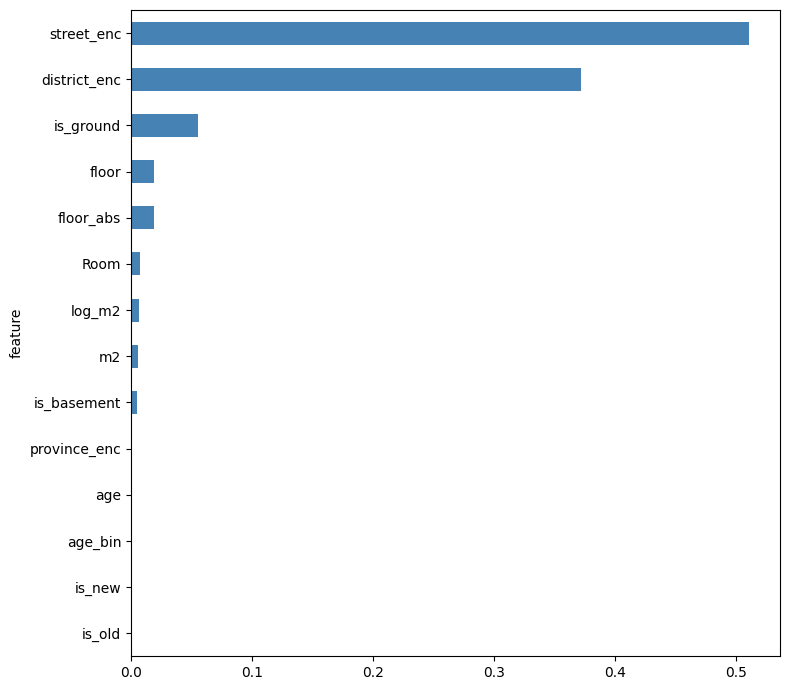

In [10]:
# Hücre 7 — Feature importance (en iyi model)
if best_model_so_far is not None and best_feats_so_far is not None:
    try:
        imp = (pd.DataFrame({'feature': best_feats_so_far,
                             'importance': best_model_so_far.feature_importances_})
               .sort_values('importance', ascending=False))
        print('🔍 Top 20 Feature Importance:')
        display(imp.head(20))
        imp.head(20).plot.barh(x='feature', y='importance',
                                figsize=(8,7), legend=False, color='steelblue')
        import matplotlib.pyplot as plt
        plt.gca().invert_yaxis()
        plt.tight_layout()
        plt.show()
    except AttributeError:
        print('Bu model feature_importances desteklemiyor.')


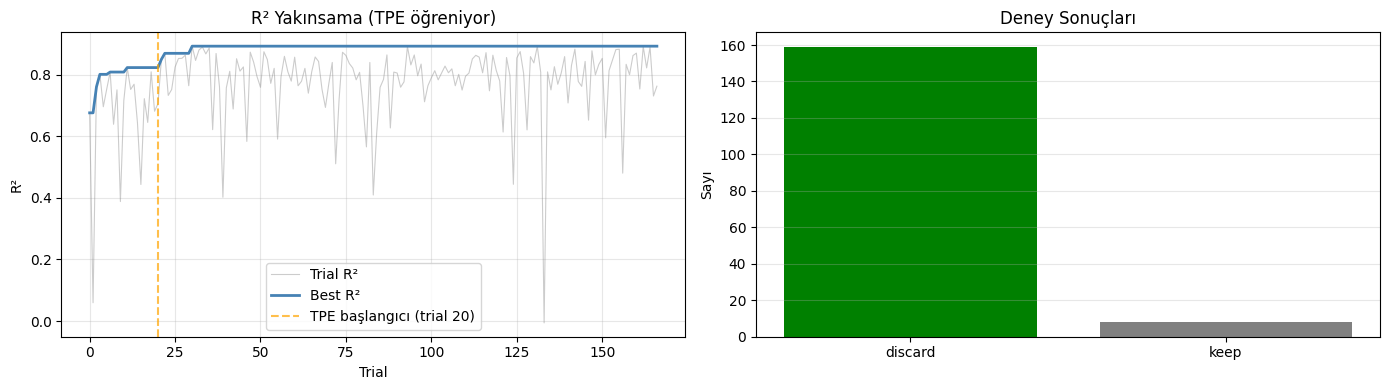

Toplam trial  : 167
Keep (iyileşme): 8
Baseline (ilk 20 random) ortalama R²: 0.666747
TPE sonrası ortalama R²             : 0.782836
İyileşme (random → TPE)             : +0.116089


In [11]:
# Hücre 8 — Optuna görselleştirme (TPE'nin öğrenme süreci)
import matplotlib.pyplot as plt

# R² yakınsama grafiği
res = pd.read_csv(RESULTS_FILE, sep='\t')
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(res['trial'], res['r2'], alpha=0.4, color='gray', lw=0.8, label='Trial R²')
axes[0].plot(res['trial'], res['best_r2'], color='steelblue', lw=2, label='Best R²')
axes[0].axvline(20, color='orange', linestyle='--', alpha=0.7, label='TPE başlangıcı (trial 20)')
axes[0].set_xlabel('Trial')
axes[0].set_ylabel('R²')
axes[0].set_title('R² Yakınsama (TPE öğreniyor)')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Status dağılımı
status_counts = res['status'].value_counts()
axes[1].bar(status_counts.index, status_counts.values,
            color=['green','gray','red'][:len(status_counts)])
axes[1].set_title('Deney Sonuçları')
axes[1].set_ylabel('Sayı')
axes[1].grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

print(f'Toplam trial  : {len(res)}')
print(f'Keep (iyileşme): {(res.status=="keep").sum()}')
print(f'Baseline (ilk 20 random) ortalama R²: {res.head(20)["r2"].mean():.6f}')
print(f'TPE sonrası ortalama R²             : {res.iloc[20:]["r2"].mean():.6f}')
print(f'İyileşme (random → TPE)             : +{res.iloc[20:]["r2"].mean() - res.head(20)["r2"].mean():.6f}')


🎯 Hangi parametre R²'yi en çok etkiliyor?


,parametre,önem
0,outlier_strategy,0.383848
1,encoding,0.239064
2,val_mode,0.169833
3,feat_set,0.088294
4,target_transform,0.043601
5,use_stats,0.027773
6,model_type,0.023874
7,n_estimators,0.015887
8,min_samples_leaf,0.007827


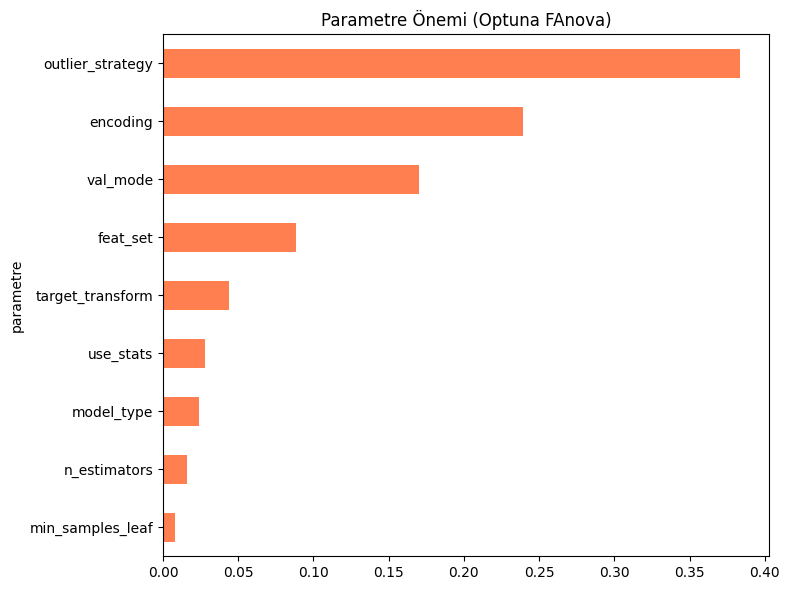

In [12]:
# Hücre 9 — Parametre önem analizi (hangi parametre R²'yi en çok etkiliyor)
try:
    importances = optuna.importance.get_param_importances(study)
    imp_df = pd.DataFrame(list(importances.items()),
                          columns=['parametre', 'önem']).sort_values('önem', ascending=False)
    print('🎯 Hangi parametre R²\'yi en çok etkiliyor?')
    display(imp_df.head(15))
    imp_df.head(15).plot.barh(x='parametre', y='önem',
                               figsize=(8,6), legend=False, color='coral')
    import matplotlib.pyplot as plt
    plt.gca().invert_yaxis()
    plt.title('Parametre Önemi (Optuna FAnova)')
    plt.tight_layout()
    plt.show()
except Exception as e:
    print(f'Parametre önemi hesaplanamadı: {e}')


In [13]:
# ── Hücre 10: Hangi teknik daha iyi? — Teknik bazlı R² karşılaştırması ──

import ast, re
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import warnings
warnings.filterwarnings('ignore')

# ── Trial verilerini oku ──────────────────────────────────────────────────
res = pd.read_csv(RESULTS_FILE, sep='\t')

# 'configuration' sütunundaki params string'ini parse et
def parse_params(s):
    try:
        # Optuna params sütunu: {'key': val, ...}
        return ast.literal_eval(str(s))
    except Exception:
        return {}

res['params_dict'] = res['configuration'].apply(parse_params)
res_ok = res[res['r2'] > 0.01].copy()   # crash olanları çıkar

def extract(col):
    return res_ok['params_dict'].apply(lambda d: d.get(col, None))

# ── Analiz edilecek teknikler ─────────────────────────────────────────────
groups = {
    'Outlier stratejisi':  ('outlier_strategy',   None),
    'Target dönüşümü':     ('target_transform',    None),
    'Encoding':            ('encoding',            None),
    'Feature seti':        ('feat_set',            None),
    'Model tipi':          ('model_type',          None),
    'Validasyon modu':     ('val_mode',            None),
    'İstatistik feature':  ('use_stats',           None),
}

fig = plt.figure(figsize=(15, 18))
fig.suptitle('Teknik bazlı R² karşılaştırması — her tekniğin medyan ve dağılımı',
             fontsize=13, y=0.98)
gs = gridspec.GridSpec(4, 2, figure=fig, hspace=0.55, wspace=0.35)

axes_positions = [(0,0),(0,1),(1,0),(1,1),(2,0),(2,1),(3,0)]

for idx, (title, (col, _)) in enumerate(groups.items()):
    ax = fig.add_subplot(gs[axes_positions[idx]])
    col_data = extract(col)
    valid = res_ok[col_data.notna()].copy()
    valid['_grp'] = col_data[col_data.notna()].values

    if len(valid) == 0:
        ax.set_title(title)
        ax.text(0.5, 0.5, 'veri yok', ha='center', transform=ax.transAxes)
        continue

    order = (valid.groupby('_grp')['r2']
             .median()
             .sort_values(ascending=False)
             .index.tolist())

    data_by_group = [valid[valid['_grp'] == g]['r2'].values for g in order]
    medians       = [v.mean() for v in data_by_group]   # medyan yerine ortalama
    colors        = plt.cm.RdYlGn(
        [(m - min(medians)) / max(max(medians) - min(medians), 1e-9)
         for m in medians])

    bp = ax.boxplot(data_by_group, patch_artist=True,
                    medianprops=dict(color='black', linewidth=1.5),
                    whiskerprops=dict(linewidth=0.8),
                    capprops=dict(linewidth=0.8),
                    flierprops=dict(marker='.', markersize=3, alpha=0.4))
    for patch, color in zip(bp['boxes'], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.8)

    ax.set_xticks(range(1, len(order)+1))
    ax.set_xticklabels(
        [f"{g}\n({round(m,4)})" for g, m in zip(order, medians)],
        fontsize=8, rotation=15, ha='right')
    ax.set_title(title, fontsize=10, fontweight='500')
    ax.set_ylabel('R²', fontsize=8)
    ax.grid(axis='y', alpha=0.3, linewidth=0.5)
    ax.spines[['top','right']].set_visible(False)

    # En iyi tekniği vurgula
    best_label = order[0]
    best_median = medians[0]
    ax.annotate(f'En iyi: {best_label}',
                xy=(1, best_median),
                xytext=(len(order)*0.5, best_median),
                fontsize=7,
                color='#2d6a2d',
                arrowprops=dict(arrowstyle='->', color='#2d6a2d', lw=0.8))

plt.savefig('teknik_karsilastirma.png', dpi=130, bbox_inches='tight',
            facecolor='white')
plt.show()
print('\n📊 Teknik sıralaması (ortalama R²):')
print('─' * 50)
for title, (col, _) in groups.items():
    col_data = extract(col)
    valid = res_ok[col_data.notna()].copy()
    valid['_grp'] = col_data[col_data.notna()].values
    if len(valid) == 0:
        continue
    ranking = (valid.groupby('_grp')['r2']
               .agg(['mean','median','count'])
               .sort_values('median', ascending=False))
    ranking.columns = ['ort_r2', 'med_r2', 'trial_sayisi']
    print(f'\n  {title}:')
    print(ranking.round(5).to_string())


KeyError: 'configuration'